In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import matplotlib.pyplot as plt
from paleta import CORES_ESTAGIO
from matplotlib.patches import Patch
from dados_atividades import load_study_activities, load_study_stages, STAGE_NAMES, STAGE_ORDER

# cores dos estágios: 4 tons mais escuros da paleta compartilhada (graphic/paleta.py)
cores_estagio = CORES_ESTAGIO

In [2]:
# estudos por estágio, contados em ../data/tabela_de_codigos.csv (dados_atividades.py)
from dados_atividades import TOTAL_ESTAGIO

valores_pizza = [TOTAL_ESTAGIO[s] for s in STAGE_ORDER]
labels_pizza = [f"T{s} — {STAGE_NAMES[s]}" for s in STAGE_ORDER]
cores_pizza = [cores_estagio[s] for s in STAGE_ORDER]

total = sum(valores_pizza)
percentuais = [round(v / total * 100) for v in valores_pizza]

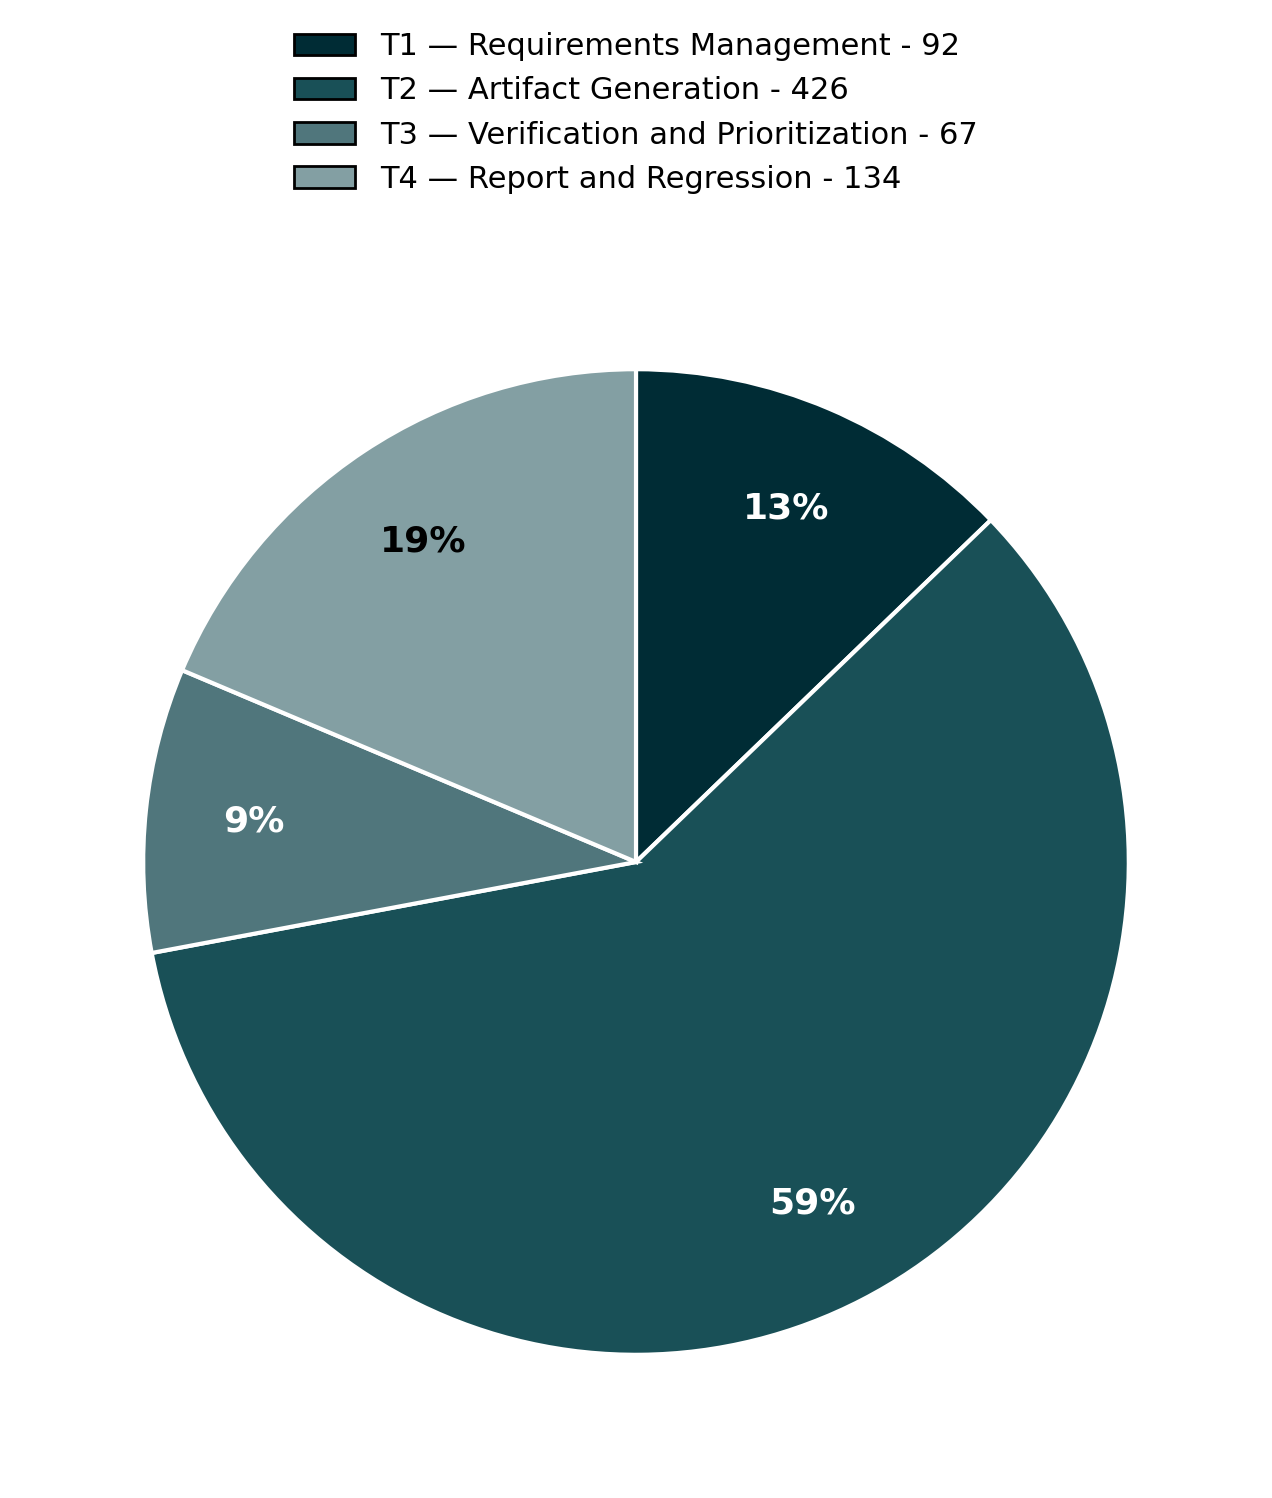

In [3]:
rotulos = [f"{l} - {p}%" for l, p in zip(labels_pizza, percentuais)]

fig, ax = plt.subplots(figsize=(10, 8), dpi=200)

wedges, textos, autotextos = ax.pie(
    valores_pizza,
    colors=cores_pizza,
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.0f}%",
    pctdistance=0.78,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontsize": 13, "fontweight": "bold"},
)

for wedge, autotext in zip(wedges, autotextos):
    r, g, b, _ = wedge.get_facecolor()
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    autotext.set_color("black" if luminancia > 0.55 else "white")

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", label=f"{l} - {v}")
    for l, cor, v in zip(labels_pizza, cores_pizza, valores_pizza)
]
ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=1,
    frameon=False,
    fontsize=11,
)

ax.set_aspect("equal")
ax.axis("off")

plt.savefig("estagios_pizza.png", bbox_inches="tight", dpi=200)
plt.show()